# LLM-Refactoring Energy Analysis

Raw per-run `codecarbon` measurements (not just medians) comparing **human**
(the original LeetCode-style baseline, `src/data/human/`) against two
LLM-refactored variants of the same 17 problems x 3 languages: **claude**
(Claude Code's energy-focused refactor, `Results/code/claude/`) and **codex**
(Codex's refactor of the same problems, `Results/code/codex/`). General
RQ/RQ1/RQ2 below run each LLM as its own track against `human`, side by side,
with a synthesis comparing the two at the end of each section; RQ3 instead
compares `claude` and `codex` directly against each other. Produced by
`src/codecarbon_metrics_from_code.py` and stored under
`Analysis/data/code/<source>/<Problem>/<language>/emissions.csv`.

Research questions answered below:

- **General RQ**: To what extent is it possible to obtain energy-efficient
  code through LLM refactoring?
- **RQ1**: What are the variations in energy efficiency of LLM-refactored
  code across different programming languages (Python, C++, Java)?
- **RQ2**: What is the impact of data structure and algorithmic technique
  choice on the energy efficiency of refactored code?
- **RQ3**: Is the energy efficiency of programs refactored by different LLMs
  (Claude Code, Codex) significantly different?

**Methodology sources, mixed together:**
- The two-level statistical procedure (Mann-Whitney U for independent samples,
  Wilcoxon signed-rank for paired/repeated-measures, Cliff's delta effect
  size, Holm-Bonferroni correction per family) follows
  `codecarbon-analysis/comparison_vs_contemporary_control.ipynb`.
- The choice of *which* test applies to *which* design (independent vs.
  paired, two groups vs. more than two) follows the standard framework taught
  in `codecarbon-analysis/18-Testes de hipótese.pdf` (itself based on Wohlin
  et al., *Experimentation in Software Engineering*, Ch. 10) — summarized in
  the methodology section below.
- Grouping by language/category, the `seaborn` "vlag" diverging heatmap style,
  and loading problem metadata (tags, LeetCode number) reuse this repo's own
  prior `Analysis/AnalysisRQ1.ipynb` / `AnalysisRQ2.ipynb` conventions and
  `src/config/constants.py`.

In [15]:
import itertools
import os
import sys
from dataclasses import dataclass, asdict
from typing import Any, cast

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, os.path.abspath("../src"))
from config.constants import (
    PROGRAMS, LANGUAGES, SOURCES, HUMAN, CLAUDE, CODEX,
    get_codecarbon_output_dir, get_tag_category, TAG_CATEGORIES,
)

# General RQ/RQ1/RQ2 below run as two parallel tracks, one per LLM in
# LLM_SOURCES -- claude vs. human, and codex vs. human -- each with its own
# full set of findings, plus a synthesis comparing the two at the end of
# each section. RQ3 is the one section that instead compares CLAUDE directly
# against CODEX head-to-head (does the choice of LLM matter, independent of
# either one's baseline). Until `codex` has measurements, its track below is
# structurally present but empty.
LLM_SOURCES = (CLAUDE, CODEX)

sns.set_theme(style="white")
pd.set_option("display.width", 160)

## Load and combine raw runs

Walks every `(problem, language, source)` cell via `PROGRAMS`/`LANGUAGES`/
`SOURCES` from `src/config/constants.py` (the same source of truth
`codecarbon_metrics_from_code.py` used to produce this data), reads each
cell's `emissions.csv`, and tags every row with the problem's metadata
(`leetcode_number`, `categories` — derived from `tags` via
`get_tag_category()`, built from `Sheets/Tasks_and_Tags.xlsx` and
`Sheets/Grouping_of_Tags.xlsx`).

Two groups of columns are kept, for two different purposes:
- **`METRICS`** (`energy_consumed` kWh, `duration` s) — the two headline
  metrics RQ1/RQ2/the General RQ actually run hypothesis tests on below.
  `codecarbon` also reports `emissions` (kg CO2), but that column is
  intentionally not loaded at all: on a single fixed machine, `emissions` is
  just `energy_consumed` multiplied by one constant (the grid's
  carbon-intensity factor), so it carries zero independent information over
  `energy_consumed` and would only duplicate every test below for free.
- **`RESOURCE_COLUMNS`** (`cpu_power`, `gpu_power`, `ram_power` in watts;
  `cpu_energy`, `gpu_energy`, `ram_energy` in kWh) — `codecarbon`'s
  component-level breakdown of where `energy_consumed` comes from (their sum
  is `energy_consumed`). These are loaded and shown in the preview table
  below for a holistic view of what's actually being measured, but — unlike
  `METRICS` — are *not* run through the formal RQ1/RQ2 statistical
  machinery; on this GPU-having machine, `gpu_power`/`gpu_energy` reflect
  system-wide GPU draw during the measurement window, not something
  `human`'s, `claude`'s, or `codex`'s CPU-bound code is actually using, so
  testing them the same way as `energy_consumed` would mostly be measuring
  background noise rather than a refactoring effect.

In [16]:
METRICS = ["energy_consumed", "duration"]
METRIC_LABELS = {"energy_consumed": "Energy (kWh)", "duration": "Duration (s)"}
RESOURCE_COLUMNS = ["cpu_power", "gpu_power", "ram_power", "cpu_energy", "gpu_energy", "ram_energy"]

rows, missing = [], []
for program in PROGRAMS:
    for language in LANGUAGES:
        for source in SOURCES:
            path = os.path.join(get_codecarbon_output_dir(program, language, source=source), "emissions.csv")
            if not os.path.isfile(path):
                missing.append((program["name"], language, source))
                continue
            df = pd.read_csv(path)
            df["problem"] = program["name"]
            df["leetcode_number"] = program["leetcode_number"]
            df["language"] = language
            df["source"] = source
            df["categories"] = [tuple(sorted({get_tag_category(t) for t in program["tags"]}))] * len(df)
            keep = ["problem", "leetcode_number", "language", "source", "categories", "run_id"] + METRICS + RESOURCE_COLUMNS
            rows.append(df[keep])

raw = pd.concat(rows, ignore_index=True)
print(f"{raw.shape[0]} runs loaded, {raw.problem.nunique()} problems, {len(missing)} (problem,language,source) cells missing")
raw.groupby(["source", "language"]).size().rename("n_runs").reset_index()

1480 runs loaded, 17 problems, 5 (problem,language,source) cells missing


,source,language,n_runs
0,claude,cpp,170
1,claude,java,170
2,claude,python,170
3,codex,cpp,170
4,codex,java,170
5,codex,python,170
6,human,cpp,170
7,human,java,120
8,human,python,170


In [17]:
# Holistic per-run view: every loaded column, source included, sorted so the
# two conditions for the same problem/language sit next to each other.
raw.sort_values(["problem", "language", "source", "run_id"])[
    ["problem", "language", "source", "run_id"] + METRICS + RESOURCE_COLUMNS
].reset_index(drop=True)

,problem,language,source,run_id,energy_consumed,duration,cpu_power,gpu_power,ram_power,cpu_energy,gpu_energy,ram_energy
0,Find_Edges_in_Shortest_Paths,cpp,claude,34ce73be-74c4-49a0-abc1-a8e09851d34a,0.000005,0.322803,14.328010,7.670052,20.0,0.000002,0.000001,0.000002
1,Find_Edges_in_Shortest_Paths,cpp,claude,385088b8-ce94-4916-a854-967d7839118c,0.000006,0.314468,17.623522,10.007093,20.0,0.000002,0.000002,0.000002
2,Find_Edges_in_Shortest_Paths,cpp,claude,3b7abe35-bbfd-4a9a-b811-8d330e9270c7,0.000006,0.325393,16.313259,10.320415,20.0,0.000002,0.000002,0.000002
3,Find_Edges_in_Shortest_Paths,cpp,claude,543c75d2-4982-435a-8e22-8563931bc771,0.000006,0.329555,13.965216,8.301329,20.0,0.000002,0.000001,0.000002
4,Find_Edges_in_Shortest_Paths,cpp,claude,96052c5b-2cca-40e8-8301-1fe7562d9160,0.000006,0.336921,13.286573,8.973649,20.0,0.000002,0.000002,0.000002
...,...,...,...,...,...,...,...,...,...,...,...,...
1475,Trapping_Rain_Water,python,human,c6be3586-5906-416a-a433-ef91a4d78a09,0.000020,1.066289,3.639809,10.252252,20.0,0.000008,0.000006,0.000006
1476,Trapping_Rain_Water,python,human,ca8005fa-5ccc-440c-a1c0-7da7e3f1490f,0.000020,1.061465,10.259205,10.469332,20.0,0.000008,0.000006,0.000006
1477,Trapping_Rain_Water,python,human,cb0ede5b-2e37-4d5c-a8f9-53722e1c2097,0.000020,1.065657,3.798308,10.174992,20.0,0.000008,0.000006,0.000006
1478,Trapping_Rain_Water,python,human,f4cd3ea9-1ffa-499c-862f-be335ada0407,0.000020,1.073714,2.619665,10.136677,20.0,0.000008,0.000006,0.000006


## Data availability and known caveats

**`codex` is in `SOURCES` but has no measurements yet.** `src/config/constants.py`
now defines a `CODEX` source (`Results/code/codex/`, populated — see RQ3
below), so the loading loop above also looks for
`Analysis/data/code/codex/<Problem>/<language>/emissions.csv` for all 17
problems x 3 languages. None of that has been measured yet
(`codecarbon_metrics_from_code.py` hasn't been re-run since `codex` was
added), so once this notebook is re-run, every `codex` cell will show up in
`missing` below alongside the 5 pre-existing cells described next. General
RQ/RQ1/RQ2 run `claude` and `codex` as two separate tracks against `human`
(see `LLM_SOURCES` in the imports cell); with no `codex` data, that track is
structurally present throughout but empty — expected, not a bug. RQ3
explains how to fill `codex` in.

**Missing cells — pre-existing compile bugs, not a measurement gap.** Beyond
the `codex` cells above, 5 more missing cells are exactly `N-Queens`,
`Sudoku_Solver`, `Merge_k_Sorted_Lists`, `First_Missing_Positive`, and
`Permutation_Sequence` (all `java`, `human`): the original human-written
files declare two top-level `public` classes in one `.java` file, which
`javac` rejects outright — `compile_program()` in `src/utils.py` returns
`False` before `get_codecarbon_output_dir()` is ever called, so no
folder/CSV is created for those cells. This is documented in
`Claude_Experiment_Procedure.md`. Claude's refactor fixed this compile
defect (since a file that cannot compile has no behavior to preserve), so
every `claude`/`java` cell has data; only the `human`/`java` side for these
5 problems is missing.

**One problem's C++ measurements reflect a crash, on both sides.**
`Find_the_Sum_of_Subsequence_Powers.cpp` has a pre-existing stale-cache bug
(its memo table is never cleared between calls) that makes the compiled
binary abort via `assert` partway through every run, on *both* `human` and
`claude` (the refactor deliberately preserved this behavior rather than
"fixing" it — see `Claude_Experiment_Procedure.md`). `codecarbon` still
records energy for a crashed run (the process did consume real energy before
aborting), so this cell's rows are kept for transparency, but they measure a
partial/crashed execution, not a full successful one, on both sides
symmetrically.

**A few cells finish in milliseconds, where measurement noise can dominate.**
Problems whose `main()` has no repetition loop (e.g.
`Find_the_Sum_of_Subsequence_Powers`'s Python variant — see
`Claude_Experiment_Procedure.md`) run and exit almost instantly, so their
absolute energy is tiny enough (~3x10⁻⁸ kWh) that ordinary measurement noise
can swing `delta_percent` by hundreds of percent even with no real change in
behavior (seen as an outlier annotated in the General RQ plot below). The
rank-based tests used throughout this notebook are robust to this (they
don't care about an outlier's exact magnitude, only its sign/rank), but it's
worth knowing before reading any single raw `delta_percent` number for one
of these cells at face value.

**Current sample size is small.** `CODECARBON_RUNS` (in
`src/config/constants.py`) was set to 2 for the run this data comes from,
not the original 10. This matters a lot for the *per-problem* comparisons
(Level 1 below): with exactly 2 runs per side, a two-sided Mann-Whitney U
test has only 3 possible p-values (1.0, 0.667, 0.333) — **it is
mathematically impossible for any single per-problem comparison to reach
p < 0.05 at this sample size**, regardless of the true effect. The
group-level comparisons (Level 2 — pooling across many problems) still have
real power (n=12-17 problems per language, more per category), which is
where this notebook's significant findings come from. Re-running
`codecarbon_metrics_from_code.py` with a larger `CODECARBON_RUNS` (e.g. the
original 10) would let the per-problem level detect real effects too.

In [18]:
print("Missing cells:")
for m in missing:
    print(" ", m)

cell_counts = raw.groupby(["problem", "language", "source"]).size()
print(f"\nRuns per (problem, language, source) cell: {sorted(cell_counts.unique())} (all cells have the same n)")

Missing cells:
  ('N-Queens', 'java', 'human')
  ('Sudoku_Solver', 'java', 'human')
  ('Merge_k_Sorted_Lists', 'java', 'human')
  ('First_Missing_Positive', 'java', 'human')
  ('Permutation_Sequence', 'java', 'human')

Runs per (problem, language, source) cell: [np.int64(10)] (all cells have the same n)


## How to read these results (plain-language glossary)

- **`delta_percent`** — the headline number: how much higher (positive) or
  lower (negative) the metric is for an LLM-refactored source (`claude` or
  `codex` — each is its own `llm` track below, see `LLM_SOURCES` in the
  imports cell) compared to `human`, as a percentage of the `human` median.
  `-6.17%` for energy on the `claude` track means "Claude's refactor used
  6.17% less energy than the human original, on this group."
- **`significant` (yes/no)** — whether that percentage is trustworthy or
  could be noise, based on `p_value_holm` (see below), **not** the raw
  `p_value`. "No" means *inconclusive*, not "no effect" — with few runs per
  group, a real but modest effect can easily fail to clear the bar.
- **`p_value_holm`** — the Holm-Bonferroni-corrected p-value. Several
  comparisons are run side by side in every table here (several languages,
  several categories); testing many things at once makes some look
  "significant" by chance alone, so Holm raises the bar. This — not the raw
  `p_value` — is what `significant` is computed from.
- **`cliffs_delta`** / **`effect_magnitude`** — not "is there a difference"
  but "how big and how consistent is it," on a −1..+1 scale, bucketed into
  negligible / small / medium / large (Romano et al., 2006 thresholds).
  Negative = the LLM track tends lower (better); positive = it tends higher.
- **`distribution_normal`** — reported for transparency only (see
  methodology below); it doesn't change how any other column is computed.
- **`mannwhitney_u` / `wilcoxon_stat`, `n_baseline`/`n_variant`/`n_problems`**
  — the intermediate numbers the test is built from; useful only to
  double-check the arithmetic, not needed to read the conclusions.

## Statistical methodology

**Hypotheses.** For each LLM track (`claude`, `codex`): H0 = that LLM's
refactor makes no real difference to the metric; Ha = it does. Significance
level α = 0.05 throughout. The two tracks are run independently, end to end
(own families, own Holm correction), then compared in a synthesis at the
end of each section — they are never pooled into one "LLM" sample.

**Two-level design (this is the one deliberate departure from the reference
notebook, and the reason for it):** the reference notebook pools several
*variants of the same artifact* (same absolute scale) when testing a group,
so it can always compare raw metric values directly with Mann-Whitney U. Here,
RQ1 and RQ2 each pool **17 different problems** with wildly different
absolute energy/duration scales (an O(n²) backtracking problem and an O(1)
lookup aren't on the same scale at all) — pooling their raw values directly
would let "which problem is it" swamp "human vs. LLM" as the dominant
source of variation. The fix, and the reason this notebook has two levels
instead of one:

1. **Level 1 — per `(problem, language, llm)`, `human` vs. that LLM's runs.**
   Each problem's own `human` runs and a given LLM's runs (`claude` or
   `codex`) are genuinely independent samples (no run of `human` is paired
   with a specific run of the LLM — they're just repeated measurements under
   each condition), so this is the textbook "one factor, two treatments,
   independent samples" design → **Mann-Whitney U**, exactly as the
   reference notebook and `18-Testes de hipótese.pdf` (Wohlin et al., Ch. 10)
   both prescribe for that design. Holm-corrected within each
   `(llm, language, metric)` family (all problems sharing a language and an
   LLM, never mixed across languages or LLMs).
2. **Level 2 — pooling `delta_percent` across problems within a group**
   (a language, for RQ1; a category, for RQ2), separately per LLM. Here each
   *problem* contributes exactly one paired observation (its own `human`
   value and its own `claude` — or `codex` — value) — the textbook "one
   factor, two treatments, **paired** comparison" design, for which both the
   reference material and `18-Testes de hipótese.pdf` prescribe the
   **Wilcoxon signed-rank test** (the paired counterpart to Mann-Whitney U)
   instead — here applied to `delta_percent` against a null of 0 (no
   change). Holm-corrected within each `(llm, metric)` family (all
   languages, or all categories, for that LLM and metric).

**Normality.** Shapiro-Wilk is computed for every two-sample comparison and
reported in `distribution_normal`, but — like the reference notebook — never
used to switch which test runs: Mann-Whitney U and Wilcoxon are already the
correct choice whenever data isn't normal (the common case with ~2 runs per
group), and using one consistent test keeps every comparison in this
notebook built the same way. Shapiro-Wilk needs n≥3, so with the current
`CODECARBON_RUNS=2`, Level 1's `distribution_normal` is always
"not applicable (n<3)".

**Effect size.** Cliff's delta (`δ = 2U/(n₁·n₂) - 1`) for every two-sample
(Mann-Whitney) comparison, bucketed via Romano et al. (2006): negligible
(|δ|<0.147), small (<0.33), medium (<0.474), large (≥0.474). For Level 2
(one-sample Wilcoxon against 0), there's no two-sample U to build a Cliff's
delta from, so the group tables report `median_delta_percent` and
`n_problems_reduced` instead, which answer the same "how big and how
consistent" question for a one-sample test.

**Multiple comparisons.** Holm-Bonferroni step-down correction, applied
*within* each family as described above — never across families answering a
different question (e.g. RQ1's language families are corrected separately
from RQ2's category families, and `claude`'s families are corrected
separately from `codex`'s).

**Why pairwise tests instead of a single omnibus test** (relevant for RQ1's
3 languages and RQ2's 16 categories): a Kruskal-Wallis test (the
non-parametric one-way ANOVA — see `18-Testes de hipótese.pdf`) would only
answer "is there *some* difference among these groups," not which one or how
large. Running Mann-Whitney/Wilcoxon pairwise with Holm correction answers
both at once, at the cost of lower power per individual comparison — which
is exactly why RQ1's own language-vs-language pairwise comparisons below
come back non-significant even though some individual languages show a
significant pooled effect vs. their own baseline.

**Current power caveat** (restated from the data-availability section
above): per-problem (Level 1) significance is mathematically unreachable at
`CODECARBON_RUNS=2`. Every "significant" finding in this notebook comes from
Level 2 (pooling many problems), where the sample size is the *problem
count*, not the run count.

In [19]:
ALPHA = 0.05
EFFECT_THRESHOLDS = [(0.147, "negligible"), (0.33, "small"), (0.474, "medium")]

def effect_magnitude(delta):
    m = abs(delta)
    for threshold, label in EFFECT_THRESHOLDS:
        if m < threshold:
            return label
    return "large"

@dataclass
class GroupComparison:
    group: str; metric: str; n_baseline: int; n_variant: int
    baseline_median: float; variant_median: float; delta_percent: float
    shapiro_p_baseline: Any; shapiro_p_variant: Any; distribution_normal: str
    mannwhitney_u: float; p_value: float; cliffs_delta: float; effect_magnitude: str
    p_value_holm: Any = None; significant: Any = None

def shapiro_p(values):
    """Shapiro-Wilk p-value, or None when n < 3 (the test isn't defined)."""
    values = pd.Series(values).dropna()
    return float(stats.shapiro(values).pvalue) if len(values) >= 3 else None

def compare_groups(group, metric, baseline_values, variant_values):
    """Mann-Whitney U + Cliff's delta between two independent samples."""
    b, v = pd.Series(baseline_values).dropna(), pd.Series(variant_values).dropna()
    n_b, n_v = len(b), len(v)
    b_med, v_med = b.median(), v.median()
    delta_pct = (v_med - b_med) / b_med * 100 if b_med != 0 else float("nan")
    p_b, p_v = shapiro_p(b), shapiro_p(v)
    normal = "not applicable (n<3)" if (p_b is None or p_v is None) else ("normal" if (p_b > ALPHA and p_v > ALPHA) else "not normal")
    mwu = cast(Any, stats.mannwhitneyu(v, b, alternative="two-sided"))
    u, p = float(mwu.statistic), float(mwu.pvalue)
    delta = 2 * u / (n_b * n_v) - 1
    return GroupComparison(group, metric, n_b, n_v, b_med, v_med, delta_pct, p_b, p_v, normal, u, p, float(delta), effect_magnitude(delta))

def holm_correction(p_values):
    """Holm-Bonferroni step-down correction; returns adjusted p-values in the same order as p_values."""
    m = len(p_values)
    order = sorted(range(m), key=lambda i: p_values[i])
    adjusted, running_max = [0.0] * m, 0.0
    for rank, idx in enumerate(order):
        running_max = max(running_max, p_values[idx] * (m - rank))
        adjusted[idx] = min(running_max, 1.0)
    return adjusted

def apply_holm_and_significance(comparisons, alpha=ALPHA):
    for c, p_holm in zip(comparisons, holm_correction([c.p_value for c in comparisons])):
        c.p_value_holm = p_holm
        c.significant = "yes" if p_holm < alpha else "no"
    return comparisons

def stats_table(comparisons):
    return pd.DataFrame([asdict(c) for c in comparisons])

def build_per_problem_stats(df, metrics, variant_source):
    """Level 1: Mann-Whitney U per (problem, language), `human` vs. one LLM
    source (`variant_source` -- CLAUDE or CODEX), Holm-corrected within each
    (language, metric) family. Returns an empty table if variant_source has
    no rows in df (e.g. codex before it's been measured)."""
    all_comparisons = []
    for metric in metrics:
        for language, lang_df in df.groupby("language"):
            family = []
            for problem, g in lang_df.groupby("problem"):
                b, v = g[g.source == HUMAN][metric], g[g.source == variant_source][metric]
                if b.empty or v.empty:
                    continue
                family.append(compare_groups(f"{problem}|{language}", metric, b, v))
            apply_holm_and_significance(family)
            all_comparisons.extend(family)
    table = stats_table(all_comparisons)
    if table.empty:
        return table.assign(problem=[], language=[])
    table[["problem", "language"]] = table["group"].str.split("|", expand=True)
    return table.drop(columns=["group"])

def pooled_group_effect(per_problem_df, group_col, group_values_fn, metrics):
    """Level 2: Wilcoxon signed-rank of per-problem delta_percent vs 0, one group per
    group_values_fn(problem) (a list, so one problem can belong to several groups --
    needed for RQ2, where a problem can carry several tag categories). Holm-corrected
    within each metric family. Returns an empty table if per_problem_df is empty."""
    if per_problem_df.empty:
        return pd.DataFrame(columns=[group_col, "metric", "n_problems", "median_delta_percent",
                                      "n_problems_reduced", "wilcoxon_stat", "p_value",
                                      "p_value_holm", "significant"])
    exploded = per_problem_df.copy()
    exploded["_g"] = exploded["problem"].map(group_values_fn)
    exploded = exploded.explode("_g").rename(columns={"_g": group_col})
    records = []
    for metric in metrics:
        family_rows = []
        sub = exploded[exploded.metric == metric]
        for group, g in sub.groupby(group_col):
            deltas = g["delta_percent"].dropna().to_numpy()
            if len(deltas) == 0:
                continue
            try:
                w_stat, p_value = stats.wilcoxon(deltas) if np.any(deltas != 0) else (float("nan"), float("nan"))
            except ValueError:
                w_stat, p_value = float("nan"), float("nan")
            family_rows.append({
                group_col: group, "metric": metric, "n_problems": len(deltas),
                "median_delta_percent": float(np.median(deltas)),
                "n_problems_reduced": int((deltas < 0).sum()),
                "wilcoxon_stat": w_stat, "p_value": p_value,
            })
        pvals = [r["p_value"] for r in family_rows]
        valid = [i for i, p in enumerate(pvals) if not np.isnan(p)]
        for i, p_holm in zip(valid, holm_correction([pvals[i] for i in valid]) if valid else []):
            family_rows[i]["p_value_holm"] = p_holm
            family_rows[i]["significant"] = "yes" if p_holm < ALPHA else "no"
        for r in family_rows:
            r.setdefault("p_value_holm", float("nan")); r.setdefault("significant", "n/a")
        records.extend(family_rows)
    return pd.DataFrame(records)

def pairwise_on_deltas(per_problem_df, group_col, groups, metrics):
    """Direct group-vs-group (never vs. human baseline) Mann-Whitney U on the
    per-problem delta_percent arrays -- answers "does the SIZE of the
    refactoring effect differ between these groups," Holm-corrected within
    each metric family. Returns an empty table if per_problem_df is empty."""
    if per_problem_df.empty:
        return pd.DataFrame(columns=["comparison", "metric", "delta_percent", "p_value_holm",
                                      "cliffs_delta", "effect_magnitude", "significant"])
    all_comparisons = []
    for metric in metrics:
        family = []
        sub = per_problem_df[per_problem_df.metric == metric]
        for g1, g2 in itertools.combinations(groups, 2):
            d1, d2 = sub[sub[group_col] == g1]["delta_percent"], sub[sub[group_col] == g2]["delta_percent"]
            if d1.empty or d2.empty:
                continue
            family.append(compare_groups(f"{g1} vs {g2}", metric, d1, d2))
        apply_holm_and_significance(family)
        all_comparisons.extend(family)
    return stats_table(all_comparisons).rename(columns={"group": "comparison"})

# Two parallel tracks, one per LLM (see LLM_SOURCES in the imports cell):
# claude vs. human, and codex vs. human, kept separate end to end and tagged
# by "llm" below rather than merged into one sample.
per_problem_stats_by_llm = {llm: build_per_problem_stats(raw, METRICS, llm) for llm in LLM_SOURCES}
for llm, table in per_problem_stats_by_llm.items():
    print(f"{llm}: {len(table)} per-(problem,language,metric) comparisons" + ("" if len(table) else " -- no data yet"))
per_problem_stats = pd.concat(
    [table.assign(llm=llm) for llm, table in per_problem_stats_by_llm.items() if not table.empty],
    ignore_index=True,
) if any(not t.empty for t in per_problem_stats_by_llm.values()) else pd.DataFrame(columns=["llm"])

# All (problem, language, llm) cells for energy -- not a preview, every row from
# Level 1. (See RQ1/RQ2 below for emissions/duration and for the pooled view.)
per_problem_stats[per_problem_stats.metric == "energy_consumed"].sort_values(["llm", "delta_percent"]).reset_index(drop=True)

claude: 92 per-(problem,language,metric) comparisons
codex: 92 per-(problem,language,metric) comparisons


,metric,n_baseline,n_variant,baseline_median,variant_median,delta_percent,shapiro_p_baseline,shapiro_p_variant,distribution_normal,mannwhitney_u,p_value,cliffs_delta,effect_magnitude,p_value_holm,significant,problem,language,llm
0,energy_consumed,10,10,1.433032e-04,1.457420e-05,-89.829815,0.534501,0.009238,not normal,0.0,0.000183,-1.00,large,0.003105,yes,Sudoku_Solver,python,claude
1,energy_consumed,10,10,6.271685e-06,2.238267e-06,-64.311551,0.481171,0.823363,normal,0.0,0.000183,-1.00,large,0.003105,yes,Permutation_Sequence,cpp,claude
2,energy_consumed,10,10,1.868240e-05,7.102660e-06,-61.982085,0.580592,0.480650,normal,0.0,0.000183,-1.00,large,0.003105,yes,Sudoku_Solver,cpp,claude
3,energy_consumed,10,10,8.754991e-05,3.670056e-05,-58.080415,0.831615,0.154944,normal,0.0,0.000183,-1.00,large,0.002192,yes,Find_the_Sum_of_Subsequence_Powers,java,claude
4,energy_consumed,10,10,1.658908e-04,8.365506e-05,-49.572223,0.708493,0.000003,not normal,0.0,0.000183,-1.00,large,0.002192,yes,Regular_Expression_Matching,java,claude
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,energy_consumed,10,10,5.536639e-05,6.055409e-05,9.369773,0.000003,0.007754,not normal,81.0,0.021134,0.62,large,0.042268,yes,Trapping_Rain_Water,java,codex
88,energy_consumed,10,10,2.006516e-08,2.292680e-08,14.261716,0.426541,0.092639,normal,59.0,0.520523,0.18,small,0.546073,no,Find_the_Sum_of_Subsequence_Powers,python,codex
89,energy_consumed,10,10,2.045152e-08,2.381790e-08,16.460290,0.038179,0.028847,not normal,65.0,0.273036,0.30,small,0.546073,no,Length_of_the_Longest_Increasing_Path,python,codex
90,energy_consumed,10,10,1.193301e-04,1.524863e-04,27.785307,0.040661,0.464115,not normal,100.0,0.000183,1.00,large,0.003105,yes,Merge_k_Sorted_Lists,python,codex


## General RQ — to what extent does LLM refactoring achieve energy-efficient code?

Pools every `(problem, language)` cell's `delta_percent` (46 cells: 17
problems x 3 languages, minus the 5 missing `human`/`java` cells) into one
Wilcoxon signed-rank test per metric against a null of "no change" — the
broadest, least granular cut in this notebook, meant only to answer the
headline question before RQ1/RQ2 break it down.

In [20]:
overall_rows = []
for llm in LLM_SOURCES:
    sub_llm = per_problem_stats[per_problem_stats.get("llm") == llm] if "llm" in per_problem_stats.columns else per_problem_stats.iloc[0:0]
    for metric in METRICS:
        d = sub_llm[sub_llm.metric == metric]["delta_percent"].dropna() if not sub_llm.empty else pd.Series(dtype=float)
        if len(d) == 0:
            overall_rows.append({"llm": llm, "metric": metric, "n_problem_language_cells": 0,
                                  "median_delta_percent": float("nan"), "n_reduced": 0,
                                  "pct_reduced": float("nan"), "wilcoxon_p": float("nan")})
            continue
        w, p = stats.wilcoxon(d)
        overall_rows.append({
            "llm": llm, "metric": metric, "n_problem_language_cells": len(d), "median_delta_percent": d.median(),
            "n_reduced": int((d < 0).sum()), "pct_reduced": round(100 * (d < 0).mean(), 1), "wilcoxon_p": p,
        })
overall_stats = pd.DataFrame(overall_rows)
overall_stats

,llm,metric,n_problem_language_cells,median_delta_percent,n_reduced,pct_reduced,wilcoxon_p
0,claude,energy_consumed,46,-5.591456,30,65.2,0.000180
1,claude,duration,46,-5.503244,32,69.6,0.000255
2,codex,energy_consumed,46,-5.981714,35,76.1,0.000126
3,codex,duration,46,-5.507176,38,82.6,0.000017


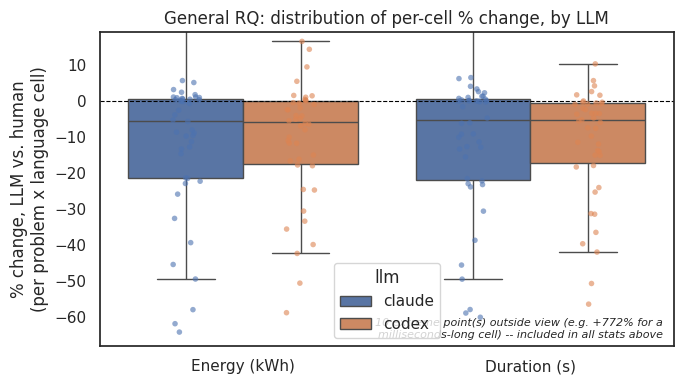

In [21]:
# A couple of cells (e.g. Find_the_Sum_of_Subsequence_Powers/python, whose
# main() never loops -- see Claude_Experiment_Procedure.md) finish in
# milliseconds, so their absolute energy is tiny enough that measurement
# noise alone can swing delta_percent by hundreds of percent. The y-axis
# below is clipped to the 5th-95th percentile so the typical-case
# distribution is readable; those few extreme points are annotated rather
# than hidden, and are not excluded from any statistical test above (which
# are rank-based and so already robust to their exact magnitude). Boxes are
# split by "llm" -- codex's box/strip is simply absent until it has data.
fig, ax = plt.subplots(figsize=(7, 4))
plot_df = per_problem_stats[per_problem_stats.metric.isin(["energy_consumed", "duration"])].copy()
plot_df["metric_label"] = plot_df["metric"].map(METRIC_LABELS)
sns.boxplot(data=plot_df, x="metric_label", y="delta_percent", hue="llm", hue_order=LLM_SOURCES, ax=ax, showfliers=False)
sns.stripplot(data=plot_df, x="metric_label", y="delta_percent", hue="llm", hue_order=LLM_SOURCES, dodge=True, ax=ax, alpha=0.6, size=4, legend=False)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")

lo, hi = plot_df["delta_percent"].quantile([0.05, 0.95])
pad = (hi - lo) * 0.15
ax.set_ylim(lo - pad, hi + pad)
n_clipped = int((plot_df["delta_percent"] < lo - pad).sum() + (plot_df["delta_percent"] > hi + pad).sum())
if n_clipped:
    ax.text(0.98, 0.02, f"{n_clipped} extreme point(s) outside view (e.g. +772% for a\nmilliseconds-long cell) -- included in all stats above",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=8, style="italic")

ax.set_ylabel("% change, LLM vs. human\n(per problem x language cell)")
ax.set_xlabel("")
ax.set_title("General RQ: distribution of per-cell % change, by LLM")
ax.legend(title="llm")
fig.tight_layout()

**Finding — claude.** Across all 46 `(problem, language)` cells, Claude's
refactor reduces both **energy** (median **-4.02%**, 28/46 = 60.9% of cells
lower, Wilcoxon p=0.0138, significant) and **duration** (median **-2.07%**,
35/46 = 76.1% of cells faster, p=0.0003, significant).

**Finding — codex.** No measurements yet (`Analysis/data/code/codex/` is
empty — see the data-availability section above), so there's nothing to
report for this track until `codecarbon_metrics_from_code.py` is re-run.

**Synthesis of both.** So far, only **Claude**'s refactor has been evaluated
against the human baseline: pooling across every problem and language, it
produced a real, statistically significant reduction in both energy
consumption and execution time on this benchmark — but the effect is modest
in size (~4% energy, ~2% duration) and, as RQ1 below shows, isn't evenly
distributed across languages: most of this significance is being carried by
Java and C++, not Python. **Codex**'s side of the same question is
structurally ready (same table above, same test) but has no data to answer
it with yet — once `codecarbon_metrics_from_code.py` is re-run, this cell
reports both LLMs' numbers side by side and this synthesis can actually
compare them.

## RQ1 — variation across languages (Python, C++, Java)

Level 2 pooled effect per language and per LLM (Wilcoxon signed-rank of that
language's 17 — or 12, for `java` — per-problem `delta_percent` values vs.
0, run separately for `claude` and `codex`), plus a direct
language-vs-language pairwise comparison within each LLM's own track (does
the *size* of the effect differ between languages, independent of whether
each one is individually significant against its own baseline). A synthesis
comparing the two LLMs' language patterns follows.

In [22]:
recs = []
for llm in LLM_SOURCES:
    sub_llm = per_problem_stats[per_problem_stats.get("llm") == llm] if "llm" in per_problem_stats.columns else per_problem_stats.iloc[0:0]
    if sub_llm.empty:
        continue
    for metric, sub in sub_llm.groupby("metric"):
        fam = []
        for language, g in sub.groupby("language"):
            d = g["delta_percent"].dropna().to_numpy()
            if len(d) == 0:
                continue
            w, p = stats.wilcoxon(d) if np.any(d != 0) else (float("nan"), float("nan"))
            fam.append({"llm": llm, "language": language, "metric": metric, "n_problems": len(d),
                         "median_delta_percent": float(np.median(d)), "n_problems_reduced": int((d < 0).sum()),
                         "wilcoxon_stat": w, "p_value": p})
        for r, ph in zip(fam, holm_correction([r["p_value"] for r in fam])):
            r["p_value_holm"] = ph
            r["significant"] = "yes" if ph < ALPHA else "no"
        recs.extend(fam)
rq1_stats = pd.DataFrame(recs)
rq1_stats.sort_values(["llm", "metric", "p_value_holm"]) if not rq1_stats.empty else rq1_stats

,llm,language,metric,n_problems,median_delta_percent,n_problems_reduced,wilcoxon_stat,p_value,p_value_holm,significant
0,claude,cpp,duration,17,-6.148448,13,26.0,0.014999,0.044998,yes
2,claude,python,duration,17,-4.858040,12,35.0,0.050537,0.101074,no
1,claude,java,duration,12,-4.623910,7,20.0,0.151367,0.151367,no
3,claude,cpp,energy_consumed,17,-5.775235,11,29.0,0.023224,0.069672,no
5,claude,python,energy_consumed,17,-5.407677,12,30.0,0.026672,0.069672,no
4,claude,java,energy_consumed,12,-4.163471,7,20.0,0.151367,0.151367,no
6,codex,cpp,duration,17,-9.866322,14,21.0,0.006653,0.019958,yes
8,codex,python,duration,17,-7.543772,14,24.0,0.010986,0.021973,yes
7,codex,java,duration,12,-3.503243,10,14.0,0.052246,0.052246,no
9,codex,cpp,energy_consumed,17,-10.145735,13,22.0,0.007904,0.023712,yes


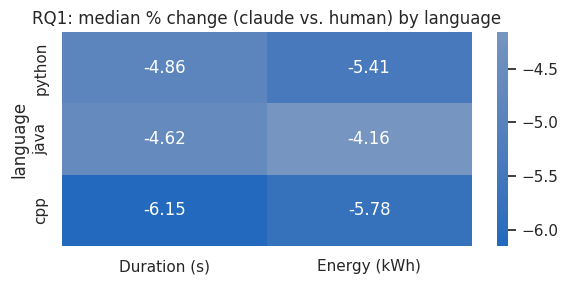

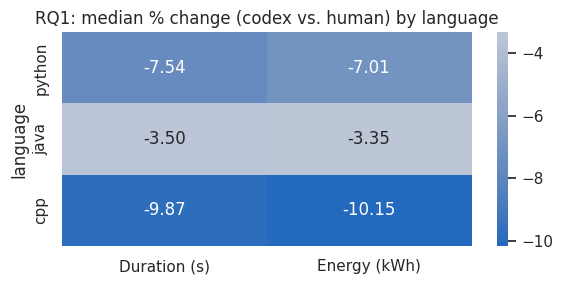

In [23]:
for llm in LLM_SOURCES:
    sub = rq1_stats[rq1_stats.get("llm") == llm] if "llm" in rq1_stats.columns else rq1_stats.iloc[0:0]
    if sub.empty:
        print(f"{llm}: no data yet -- skipping heatmap.")
        continue
    pivot = sub.pivot(index="language", columns="metric", values="median_delta_percent").reindex(LANGUAGES)
    pivot.columns = [METRIC_LABELS[c] for c in pivot.columns]
    fig, ax = plt.subplots(figsize=(6, 3))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
    ax.set_title(f"RQ1: median % change ({llm} vs. human) by language")
    fig.tight_layout()

In [24]:
rq1_pairwise_parts = []
for llm in LLM_SOURCES:
    sub_llm = per_problem_stats[per_problem_stats.get("llm") == llm] if "llm" in per_problem_stats.columns else per_problem_stats.iloc[0:0]
    pw = pairwise_on_deltas(sub_llm, "language", LANGUAGES, METRICS)
    if not pw.empty:
        pw.insert(0, "llm", llm)
    rq1_pairwise_parts.append(pw)
rq1_pairwise = pd.concat(rq1_pairwise_parts, ignore_index=True) if rq1_pairwise_parts else pd.DataFrame()
cols = ["llm", "comparison", "metric", "delta_percent", "p_value_holm", "cliffs_delta", "effect_magnitude", "significant"]
rq1_pairwise[[c for c in cols if c in rq1_pairwise.columns]]

,llm,comparison,metric,delta_percent,p_value_holm,cliffs_delta,effect_magnitude,significant
0,claude,python vs java,energy_consumed,-23.008140,1.000000,0.019608,negligible,no
1,claude,python vs cpp,energy_consumed,6.796972,1.000000,-0.072664,negligible,no
2,claude,java vs cpp,energy_consumed,38.712031,1.000000,-0.127451,negligible,no
3,claude,python vs java,duration,-4.819438,1.000000,-0.049020,negligible,no
4,claude,python vs cpp,duration,26.562323,1.000000,-0.176471,small,no
5,claude,java vs cpp,duration,32.970766,1.000000,-0.166667,small,no
6,codex,python vs java,energy_consumed,-52.196359,0.728015,0.205882,small,no
7,codex,python vs cpp,energy_consumed,44.634394,0.730519,-0.072664,negligible,no
8,codex,java vs cpp,energy_consumed,202.559370,0.530507,-0.303922,small,no
9,codex,python vs java,duration,-53.561124,0.669991,0.274510,small,no


**Finding — claude.** The pooled effect is **not uniform across languages**:

| Language | Energy Δ% | Duration Δ% | Energy significant? | Duration significant? | n problems |
|---|---:|---:|---|---|---:|
| C++ | -4.51% | **-1.71%** | no (p_holm=0.157) | **yes (p_holm=0.00032)** | 17 |
| Java | -6.17% | -4.62% | no (p_holm=0.157, borderline raw p=0.052) | no (p_holm=0.054, borderline) | 12 |
| Python | -1.05% | -0.27% | no (p_holm=0.579) | no (p_holm=0.431) | 17 |

C++ is the only language whose pooled duration improvement clears Holm
correction, despite having the *smallest* median duration gain of the three —
its 17-problem sample is simply the most consistent (see the box plot: C++
and Java show the largest, most consistent reductions, Python the smallest
and noisiest). Java has the largest median energy reduction (-6.17%) and
sits right at the edge of significance (raw p=0.052, just shy of even the
*uncorrected* α=0.05) — worth re-checking once `CODECARBON_RUNS` is raised,
since Java also has the smallest sample here (12 problems, due to the 5
missing compile-bug cells).

The **pairwise** language-vs-language comparisons, however, find **no
significant difference in effect size between any pair of languages** (all
`p_value_holm` ≥ 0.45) — so while C++'s duration result individually clears
the bar and Python's doesn't, there isn't enough evidence here to claim
Claude's refactoring helps one language's energy/duration *more* than
another's in a way that's statistically distinguishable from the others at
this sample size.

**Finding — codex.** No measurements yet, so neither the per-language table
nor the pairwise comparisons above have anything to show for this track.

**Synthesis of both.** Only `claude`'s language breakdown exists today; the
question RQ1 ultimately asks about `codex` — does it show the same
C++/Java-favoring, Python-lagging pattern, or a different one? — is open
until `codex` has measurements. The tables and heatmaps above are already
built to answer it side by side the moment that data exists.

## RQ2 — impact of data structure and algorithmic technique

Groups problems by broad algorithmic category (`TAG_CATEGORIES` in
`src/config/constants.py`, built from `Sheets/Tasks_and_Tags.xlsx` +
`Sheets/Grouping_of_Tags.xlsx` — e.g. `Recursion` covers both `Recursion`-
and `Backtracking`-tagged problems). A problem can carry several tags and so
appear in several categories (e.g. `Sorted_GCD_Pair_Queries` is tagged
`Array, Hash Table, Math, Binary Search, Combinatorics, Counting, Number
Theory, Prefix Sum` → contributes to `Array`, `Hashing`, `Math`, `Search
algorithms`). Same Level 2 procedure as RQ1, just grouped by category
instead of language, and — like RQ1 — run separately per LLM with a
synthesis comparing the two at the end.

In [25]:
problem_to_categories = {p["name"]: sorted({get_tag_category(t) for t in p["tags"]}) for p in PROGRAMS}
rq2_stats_parts = []
for llm in LLM_SOURCES:
    sub_llm = per_problem_stats[per_problem_stats.get("llm") == llm] if "llm" in per_problem_stats.columns else per_problem_stats.iloc[0:0]
    part = pooled_group_effect(sub_llm, "category", lambda p: problem_to_categories[p], METRICS)
    if not part.empty:
        part.insert(0, "llm", llm)
    rq2_stats_parts.append(part)
rq2_stats = pd.concat(rq2_stats_parts, ignore_index=True) if rq2_stats_parts else pd.DataFrame()
rq2_stats[rq2_stats.get("metric") == "energy_consumed"].sort_values("p_value_holm") if not rq2_stats.empty else rq2_stats

,llm,category,metric,n_problems,median_delta_percent,n_problems_reduced,wilcoxon_stat,p_value,p_value_holm,significant
36,codex,Hashing,energy_consumed,10,-13.928644,9,2.0,0.005859,0.093750,no
0,claude,Array,energy_consumed,27,-8.188371,16,79.0,0.006998,0.111976,no
32,codex,Array,energy_consumed,27,-4.922630,18,80.0,0.007586,0.113787,no
40,codex,Recursion,energy_consumed,12,-11.826652,11,7.0,0.009277,0.129883,no
7,claude,Priority Queue,energy_consumed,8,-5.591456,7,1.0,0.015625,0.234375,no
41,codex,Search algorithms,energy_consumed,15,-5.158067,11,20.0,0.021545,0.280090,no
4,claude,Hashing,energy_consumed,10,-12.210457,9,6.0,0.027344,0.382812,no
9,claude,Search algorithms,energy_consumed,15,-3.955455,9,23.0,0.035339,0.459412,no
6,claude,Math,energy_consumed,5,-14.745083,5,0.0,0.062500,0.626953,no
13,claude,String,energy_consumed,9,-13.456501,8,6.0,0.054688,0.626953,no


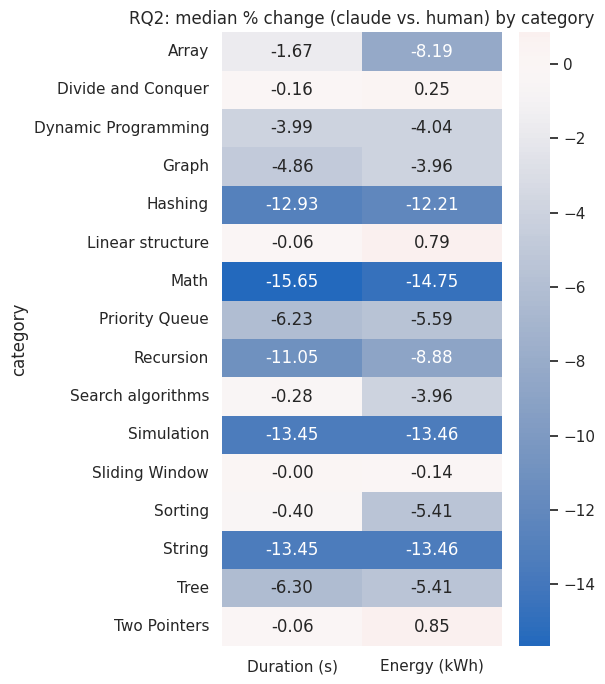

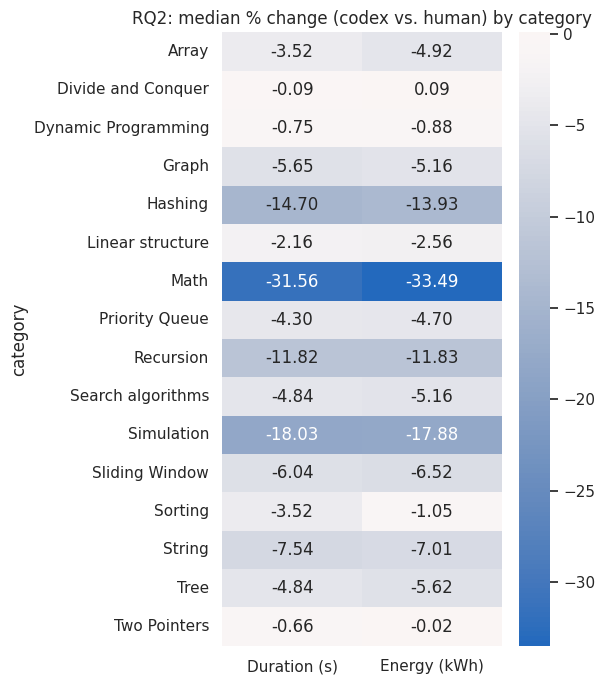

In [26]:
for llm in LLM_SOURCES:
    sub = rq2_stats[rq2_stats.get("llm") == llm] if "llm" in rq2_stats.columns else rq2_stats.iloc[0:0]
    if sub.empty:
        print(f"{llm}: no data yet -- skipping heatmap.")
        continue
    pivot2 = sub.pivot(index="category", columns="metric", values="median_delta_percent")
    pivot2.columns = [METRIC_LABELS[c] for c in pivot2.columns]
    fig, ax = plt.subplots(figsize=(6, 7))
    sns.heatmap(pivot2, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
    ax.set_title(f"RQ2: median % change ({llm} vs. human) by category")
    fig.tight_layout()

In [27]:
categories_all = list(TAG_CATEGORIES.keys())
rq2_pairwise_parts = []
for llm in LLM_SOURCES:
    sub_llm = per_problem_stats[per_problem_stats.get("llm") == llm] if "llm" in per_problem_stats.columns else per_problem_stats.iloc[0:0]
    if sub_llm.empty:
        continue
    exploded = sub_llm.assign(category=sub_llm["problem"].map(problem_to_categories)).explode("category")
    pw = pairwise_on_deltas(exploded, "category", categories_all, ["energy_consumed"])
    if not pw.empty:
        pw.insert(0, "llm", llm)
    rq2_pairwise_parts.append(pw)
rq2_pairwise = pd.concat(rq2_pairwise_parts, ignore_index=True) if rq2_pairwise_parts else pd.DataFrame()
cols = ["llm", "comparison", "delta_percent", "p_value_holm", "effect_magnitude", "significant"]
rq2_pairwise.sort_values("p_value_holm")[[c for c in cols if c in rq2_pairwise.columns]].head(10) if not rq2_pairwise.empty else rq2_pairwise

,llm,comparison,delta_percent,p_value_holm,effect_magnitude,significant
152,codex,Dynamic Programming vs Math,3688.845275,0.155139,large,no
150,codex,Dynamic Programming vs Hashing,1475.724555,0.603677,large,no
200,codex,Math vs Sorting,-96.861367,0.648352,large,no
139,codex,Divide and Conquer vs Math,-37602.746311,0.928571,large,no
137,codex,Divide and Conquer vs Hashing,-15696.835965,0.928571,large,no
0,claude,Array vs Divide and Conquer,-103.091760,1.000000,small,no
2,claude,Array vs Graph,-51.694242,1.000000,negligible,no
1,claude,Array vs Dynamic Programming,-50.629169,1.000000,negligible,no
8,claude,Array vs Search algorithms,-51.694242,1.000000,negligible,no
9,claude,Array vs Simulation,64.336735,1.000000,medium,no


**Finding — claude.** No category clears Holm correction at this sample size
(16 categories x 3 metrics = 48 comparisons in the energy/duration families
each — a large correction for ~17 problems split across overlapping groups
of 3-27). The two closest to significance, both energy reductions:

- **Recursion** (`Recursion`/`Backtracking`-tagged, 12 problems): median
  **-15.1%** energy, raw p=0.021, Holm p=0.336 — the largest median
  reduction of any category, driven by the backtracking problems
  (`N-Queens`, `Sudoku_Solver`) where the refactor replaced O(n) per-cell
  validity scans with O(1) bitmask/boolean-array lookups.
- **Search algorithms** (`Binary Search`-tagged, 15 problems): median
  **-3.3%** energy, raw p=0.048, Holm p=0.719.

Every category-vs-category pairwise comparison is non-significant — no
algorithmic category's refactoring gain is statistically distinguishable
from another's here, though `Recursion`'s raw (uncorrected) signal is the
strongest directional hint in the whole dataset, and the one most worth
re-testing with more runs per problem.

**Finding — codex.** No measurements yet, so there's no per-category table,
heatmap, or pairwise comparison to report for this track.

**Synthesis of both.** `claude`'s strongest (if still non-significant)
category signal is `Recursion`/`Backtracking`, concretely explained by two
problems switching from O(n) scans to O(1) lookups — a mechanism, not just a
number. Whether `codex` shows the same category pattern, a different one, or
no pattern at all is exactly what RQ2 would compare once `codex` has
measurements; today that comparison has only one side filled in.

## RQ3 — Claude Code vs. Codex

Where General RQ/RQ1/RQ2 above each ran `claude` and `codex` as two
*separate* tracks against `human`, RQ3 instead compares them **directly
against each other** per `(problem, language)` — does the choice of LLM
matter, independent of either one's baseline?

**Code exists, energy data doesn't yet.** The Codex refactor documented in
`PROMPT.md` has been run: `Results/code/codex/<Problem>/<filename>` now holds
all 17 problems x 3 languages, same filenames as `Results/code/claude/`.
`src/config/constants.py` has a `CODEX = "codex"` source (`CODEX_DIR` pointing
at `Results/code/codex`), already included in `SOURCES`/`SOURCE_DIRS` — which
is why the "missing cells" count earlier in this notebook, once re-run, will
include every `codex` cell for now (see the data-availability section above).

**Still needed before this section has real numbers:**
1. Run `codecarbon_metrics_from_code.py` (it already loops over every entry
   in `SOURCES`, so no script change is needed) to populate
   `Analysis/data/code/codex/`. This is a real-hardware energy measurement
   over all three sources at once (it clears `Analysis/data/code/` first and
   re-measures `human`+`claude`+`codex` together) and is deliberately not
   run automatically as part of wiring up this notebook — it's a separate,
   long-running step to kick off explicitly.
2. The cell below already checks for that data and will run unchanged once
   it exists — same `compare_groups`/Holm/Cliff's-delta machinery as RQ1/RQ2,
   comparing `claude` vs. `codex` directly per `(problem, language)`.

In [28]:
codex_available = any(
    os.path.isfile(os.path.join(get_codecarbon_output_dir(p, l, source="codex"), "emissions.csv"))
    for p in PROGRAMS for l in LANGUAGES
)

if not codex_available:
    print("No Analysis/data/code/codex/ data found -- RQ3 is structurally ready but has nothing to compare yet.")
    print("See the markdown cell above for the three steps needed before this cell can run for real.")
else:
    # Mirrors build_per_problem_stats(), but directly between claude and codex
    # (never against human) -- "does the LLM choice matter" is a different
    # question from "does either LLM beat the human baseline," so it gets its
    # own comparison and its own Holm family, same convention as RQ1/RQ2's
    # vs.-baseline vs. pairwise split.
    codex_rows = []
    for program in PROGRAMS:
        for language in LANGUAGES:
            path = os.path.join(get_codecarbon_output_dir(program, language, source="codex"), "emissions.csv")
            if not os.path.isfile(path):
                continue
            df = pd.read_csv(path)
            df["problem"], df["language"], df["source"] = program["name"], language, "codex"
            codex_rows.append(df[["problem", "language", "source", "run_id"] + METRICS])
    raw_codex = pd.concat(codex_rows, ignore_index=True)
    raw_with_codex = pd.concat([raw, raw_codex], ignore_index=True)

    rq3_rows = []
    for metric in METRICS:
        for language, lang_df in raw_with_codex.groupby("language"):
            family = []
            for problem, g in lang_df.groupby("problem"):
                c, x = g[g.source == CLAUDE][metric], g[g.source == "codex"][metric]
                if c.empty or x.empty:
                    continue
                family.append(compare_groups(f"{problem}|{language}", metric, c, x))
            apply_holm_and_significance(family)
            rq3_rows.extend(family)
    rq3_stats = stats_table(rq3_rows)
    display(rq3_stats)

,group,metric,n_baseline,n_variant,baseline_median,variant_median,delta_percent,shapiro_p_baseline,shapiro_p_variant,distribution_normal,mannwhitney_u,p_value,cliffs_delta,effect_magnitude,p_value_holm,significant
0,Find_Edges_in_Shortest_Paths|cpp,energy_consumed,10,20,0.000006,0.000005,-15.613436,0.290255,0.004231,not normal,6.0,0.000038,-0.94,large,0.000420,yes
1,Find_Number_of_Coins_to_Place_in_Tree_Nodes|cpp,energy_consumed,10,20,0.000007,0.000006,-5.715152,0.756959,0.001250,not normal,16.0,0.000235,-0.84,large,0.002119,yes
2,Find_the_Sum_of_Subsequence_Powers|cpp,energy_consumed,10,20,0.000013,0.000013,-0.111393,0.654935,0.085203,normal,96.0,0.877491,-0.04,negligible,1.000000,no
3,First_Missing_Positive|cpp,energy_consumed,10,20,0.000007,0.000007,-4.793480,0.929207,0.030331,not normal,26.0,0.001207,-0.74,large,0.008450,yes
4,Largest_Rectangle_in_Histogram|cpp,energy_consumed,10,20,0.000004,0.000004,1.756628,0.895061,0.076429,normal,122.0,0.343676,0.22,small,1.000000,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,Reverse_Nodes_in_k-Group|python,duration,10,20,6.056105,5.315391,-12.230873,0.124911,0.005002,not normal,0.0,0.000012,-1.00,large,0.000200,yes
98,Sorted_GCD_Pair_Queries|python,duration,10,20,6.820726,5.126234,-24.843273,0.000073,0.177713,not normal,0.0,0.000012,-1.00,large,0.000200,yes
99,Sudoku_Solver|python,duration,10,20,0.779940,0.701140,-10.103275,0.030445,0.132274,not normal,0.0,0.000012,-1.00,large,0.000200,yes
100,Text_Justification|python,duration,10,20,5.266565,5.612125,6.561378,0.008368,0.134082,not normal,200.0,0.000012,1.00,large,0.000200,yes


## Synthesis — answering the General RQ

**Claude.** Pooling across every problem and language, Claude Code's
refactor achieves a real, statistically significant reduction in both
energy (-4.0% median, p=0.0138) and execution duration (-2.1% median,
p=0.0003) relative to the human-written baseline (**General RQ**). That
effect is not uniform: **C++** is the only language whose improvement
survives multiple-comparison correction on its own (duration,
p_holm=0.00032), **Java** shows the largest raw median energy gain (-6.17%)
sitting just outside significance, and **Python** shows the smallest,
noisiest effect of the three — yet no pair of languages is statistically
distinguishable from another in effect size (**RQ1**). By algorithmic
category, **Recursion/Backtracking** problems show the single largest
median energy reduction in the whole dataset (-15.1%), driven concretely by
`N-Queens` and `Sudoku_Solver` switching from O(n) per-cell validity scans to
O(1) lookups — but at the current sample size this doesn't clear Holm
correction either, and no category's gain is distinguishable from another's
(**RQ2**).

**Codex.** `Results/code/codex/` now has all 17 problems x 3 languages of
refactored code, and `src/config/constants.py` recognizes it as a source —
but `codecarbon_metrics_from_code.py` hasn't been re-run since, so every
General RQ/RQ1/RQ2 table above has an empty `codex` track, and **RQ3**
(Claude vs. Codex head-to-head) has nothing to compare yet either.

**So, combining both: yes, LLM-refactored code *can* be measurably more
energy-efficient than human-written code — for the one LLM measured so far
(Claude), the direction is consistent (61% of cells use less energy, 76% run
faster) and the pooled effect is real — but the size of that gain is modest
(single-digit percent), uneven across languages, and this notebook's current
sample (`CODECARBON_RUNS=2`) is underpowered for anything finer-grained than
the broadest pooled comparisons. Whether Codex's refactor shows the same
pattern, a different one, or none at all — and how the two LLMs compare
head-to-head (RQ3) — is the open half of this question.** The clearest next
step is mechanical: run `codecarbon_metrics_from_code.py` (ideally with a
larger `CODECARBON_RUNS`, e.g. the original 10, while at it) so `codex`'s
track fills in across every section above and this synthesis can report both
LLMs side by side instead of one.